<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/sessions/Session04_groupby_merge_reshape.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۴: گروه‌بندی، ادغام و تغییر شکل جدول‌ها

بیشتر سؤال‌های کسب‌وکاری از جنس «به تفکیک» هستند: فروش **به تفکیک** شهر، میانگین امتیاز **به تفکیک** دستهٔ کالا، رشد **به تفکیک** ماه. ابزار پاسخ به همهٔ آن‌ها در این جلسه است.

### اهداف این جلسه

- الگوی **تقسیم، اعمال، ترکیب (Split-Apply-Combine)** با `groupby`
- تجمیع چندگانه با `agg` و تجمیع نام‌دار
- تفاوت `agg` و `transform`
- جدول محوری با `pivot_table` و `crosstab`
- ادغام جدول‌ها با `merge`: انواع join و خطاهای رایج
- چسباندن جدول‌ها با `concat`
- تبدیل جدول پهن و بلند با `melt` و `pivot`
- خلاصه‌سازی سری زمانی با `resample`

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. داده‌ها

از سه جدول فروشگاه اینترنتی استفاده می‌کنیم: سفارش‌های پاک‌شده (خروجی جلسهٔ ۳)، مشتری‌ها و کالاها. این ساختار، یعنی چند جدول مرتبط از طریق **کلید**، همان چیزی است که در پایگاه داده‌ها می‌بینیم.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

orders = pd.read_csv(DATA_URL + "orders_clean.csv", parse_dates=["order_date"])
customers = pd.read_csv(DATA_URL + "customers.csv", parse_dates=["signup_date"])
products = pd.read_csv(DATA_URL + "products.csv")

for name, t in [("orders", orders), ("customers", customers), ("products", products)]:
    print(f"{name:10s} {t.shape}")
orders.head(3)

orders     (1196, 10)
customers  (220, 5)
products   (21, 4)


,order_id,order_date,customer_id,city,product_id,quantity,total_price,payment_method,delivery_days,rating
0,100001,2024-03-20 13:31:00,C0103,Shiraz,P007,2,720000,card,4,5.0
1,100002,2024-03-20 13:45:00,C0151,Rasht,P001,1,2400000,card,4,4.0
2,100003,2024-03-20 16:13:00,C0132,Amol,P006,2,840000,cash_on_delivery,3,3.0


In [2]:
products.head()

,product_id,product_name,category,unit_price
0,P001,Wireless Earbuds,Electronics,2400000
1,P002,Power Bank,Electronics,1150000
2,P003,Smart Watch,Electronics,6800000
3,P004,USB-C Cable,Electronics,180000
4,P005,Bluetooth Speaker,Electronics,3200000


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. ادغام جدول‌ها با `merge`

جدول سفارش فقط `product_id` دارد؛ برای تحلیل بر اساس دستهٔ کالا باید آن را با جدول کالاها **ادغام** کنیم.

| نوع | سطرهایی که نگه داشته می‌شوند |
|---|---|
| `inner` | فقط سطرهایی که کلیدشان در **هر دو** جدول هست |
| `left` | همهٔ سطرهای جدول چپ؛ ستون‌های جدول راست در صورت نبود تطابق `NaN` |
| `right` | برعکس `left` |
| `outer` | همهٔ سطرهای هر دو جدول |

پارامتر `validate` یک محافظ مهم است: اینجا می‌گوییم هر سفارش باید **حداکثر یک** کالای متناظر داشته باشد (`many_to_one`). اگر جدول کالاها شناسهٔ تکراری داشت، به‌جای تکثیر بی‌صدای سطرها خطا می‌گیریم.

</div>

In [3]:
df = orders.merge(products, on="product_id", how="left", validate="many_to_one")
df = df.merge(customers[["customer_id", "gender", "birth_year", "signup_date"]],
              on="customer_id", how="left", validate="many_to_one")
assert len(df) == len(orders)          # a left merge must not change the row count
df.head(3)

,order_id,order_date,customer_id,city,product_id,quantity,total_price,payment_method,delivery_days,rating,product_name,category,unit_price,gender,birth_year,signup_date
0,100001,2024-03-20 13:31:00,C0103,Shiraz,P007,2,720000,card,4,5.0,Statistics Primer,Books,360000,M,1999,2023-12-19
1,100002,2024-03-20 13:45:00,C0151,Rasht,P001,1,2400000,card,4,4.0,Wireless Earbuds,Electronics,2400000,M,1995,2024-05-15
2,100003,2024-03-20 16:13:00,C0132,Amol,P006,2,840000,cash_on_delivery,3,3.0,Python Handbook,Books,420000,M,2000,2023-12-01


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### پیدا کردن سطرهای بی‌جفت با `indicator`

یک سؤال واقعی: کدام مشتری‌ها ثبت‌نام کرده‌اند ولی **هیچ** سفارشی نداده‌اند؟ ادغام `left` از سمت مشتری‌ها، به همراه `indicator=True`، ستونی می‌سازد که منشأ هر سطر را نشان می‌دهد:

</div>

In [4]:
buyers = orders[["customer_id"]].drop_duplicates()
check = customers.merge(buyers, on="customer_id", how="left", indicator=True)
print(check["_merge"].value_counts())
check.loc[check["_merge"] == "left_only", ["customer_id", "city", "signup_date"]].head()

_merge
both          198
left_only      22
right_only      0
Name: count, dtype: int64


,customer_id,city,signup_date
14,C0015,Shiraz,2024-08-18
24,C0025,Tehran,2023-02-16
200,C0201,Sari,2023-12-04
201,C0202,Sari,2024-06-09
202,C0203,Isfahan,2024-08-04


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

> **خطای رایج:** اگر کلید در هر دو جدول تکراری باشد، `merge` همهٔ ترکیب‌ها را می‌سازد (ضرب دکارتی) و تعداد سطرها ناگهان چند برابر می‌شود. همیشه بعد از ادغام، تعداد سطرها را بررسی کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. `groupby`: تقسیم، اعمال، ترکیب

`df.groupby("city")["total_price"].sum()` یعنی:

1. **تقسیم**: سطرها را بر اساس مقدار `city` به گروه‌ها تقسیم کن.
2. **اعمال**: روی ستون `total_price` هر گروه، `sum` را حساب کن.
3. **ترکیب**: نتایج را در یک `Series` با index شهرها برگردان.

</div>

In [5]:
revenue_by_city = df.groupby("city")["total_price"].sum().sort_values(ascending=False)
(revenue_by_city / 1e6).round(1)          # in million Toman

city
Tehran     956.7
Shiraz     445.3
Mashhad    422.2
Sari       369.0
Isfahan    304.0
Tabriz     286.2
Rasht      230.7
Amol       178.8
Name: total_price, dtype: float64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### چند تجمیع با هم: `agg` و تجمیع نام‌دار

با تجمیع نام‌دار (Named Aggregation) نام ستون خروجی، ستون ورودی و تابع را صریح می‌نویسیم و جدول خروجی خوانا می‌شود:

</div>

In [6]:
city_report = df.groupby("city").agg(
    orders=("order_id", "count"),
    customers=("customer_id", "nunique"),
    revenue_m=("total_price", lambda s: s.sum() / 1e6),
    avg_basket=("total_price", "mean"),
    avg_rating=("rating", "mean"),
    median_delivery=("delivery_days", "median"),
).sort_values("revenue_m", ascending=False)
city_report.round(1)

,orders,customers,revenue_m,avg_basket,avg_rating,median_delivery
city,,,,,,
Tehran,379,59,956.7,2524216.4,3.9,4.0
Shiraz,152,23,445.3,2929592.1,4.1,4.0
Mashhad,158,29,422.2,2672253.2,3.9,4.0
Sari,118,18,369.0,3127500.0,3.8,4.0
Isfahan,122,22,304.0,2491795.1,4.0,4.0
Tabriz,121,21,286.2,2365628.1,3.8,4.0
Rasht,94,16,230.7,2454148.9,4.0,4.0
Amol,52,10,178.8,3438461.5,4.0,4.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

گروه‌بندی می‌تواند بر اساس **چند** ستون هم باشد. نتیجه یک index چندسطحی (MultiIndex) دارد که با `unstack` می‌توانیم آن را به جدول دوبعدی تبدیل کنیم:

</div>

In [7]:
cat_pay = df.groupby(["category", "payment_method"])["total_price"].sum().div(1e6).round(1)
cat_pay.unstack()

payment_method,card,cash_on_delivery,unknown,wallet
category,,,,
Books,99.8,21.6,2.9,36.0
Clothing,228.1,92.3,7.8,81.8
Electronics,1027.9,258.5,NaN,275.3
Grocery,245.8,35.6,7.9,109.1
Home,384.3,87.6,2.9,187.9


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### `transform`: نتیجهٔ گروه با همان شکل دادهٔ اصلی

`agg` برای هر گروه **یک** مقدار برمی‌گرداند، اما `transform` نتیجه را به **تک‌تک سطرهای** آن گروه برمی‌گرداند. این برای مقایسهٔ هر سطر با گروهش عالی است. مثلاً: هر سفارش چند برابر میانگین سفارش‌های همان دسته است؟

</div>

In [8]:
df["category_avg"] = df.groupby("category")["total_price"].transform("mean").round()
df["vs_category"] = (df["total_price"] / df["category_avg"]).round(2)
df[["order_id", "category", "total_price", "category_avg", "vs_category"]].head()

,order_id,category,total_price,category_avg,vs_category
0,100001,Books,720000,694169.0,1.04
1,100002,Electronics,2400000,5597394.0,0.43
2,100003,Books,840000,694169.0,1.21
3,100004,Electronics,4600000,5597394.0,0.82
4,100005,Electronics,6080000,5597394.0,1.09


In [9]:
# share of each order in its customer's total spending
df["customer_total"] = df.groupby("customer_id")["total_price"].transform("sum")
df["share_of_customer"] = df["total_price"] / df["customer_total"]
print(df.groupby("customer_id")["share_of_customer"].sum().round(6).unique())   # every customer sums to 1

[1.]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### فیلتر کردن گروه‌ها

`filter` گروه‌هایی را نگه می‌دارد که شرطی را برآورده کنند. مثلاً فقط مشتری‌هایی که حداقل ۱۰ سفارش داشته‌اند:

</div>

In [10]:
loyal = df.groupby("customer_id").filter(lambda g: len(g) >= 10)
print(loyal["customer_id"].nunique(), "loyal customers,", len(loyal), "orders")

20 loyal customers, 219 orders


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. جدول محوری: `pivot_table` و `crosstab`

`pivot_table` همان جدول محوری اکسل است: یک ستون برای سطرها، یک ستون برای ستون‌ها و یک تابع تجمیع برای خانه‌ها. پارامتر `margins=True` جمع کل را اضافه می‌کند.

</div>

In [11]:
pd.pivot_table(
    df, index="city", columns="category", values="total_price",
    aggfunc="sum", margins=True, margins_name="Total",
).div(1e6).round(1)

category,Books,Clothing,Electronics,Grocery,Home,Total
city,,,,,,
Amol,8.0,22.6,118.9,12.3,17.0,178.8
Isfahan,23.6,49.2,147.9,43.2,40.1,304.0
Mashhad,20.7,31.2,204.1,62.5,103.7,422.2
Rasht,14.5,23.8,121.9,35.0,35.5,230.7
Sari,11.9,44.4,173.7,37.7,101.3,369.0
Shiraz,15.8,57.7,265.1,42.1,64.6,445.3
Tabriz,17.9,46.5,117.1,34.1,70.6,286.2
Tehran,47.9,134.7,412.9,131.4,229.8,956.7
Total,160.4,410.0,1561.7,398.3,662.6,3193.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`crosstab` برای شمارش ترکیب دو متغیر دسته‌ای است. با `normalize="index"` هر سطر به درصد تبدیل می‌شود: سهم هر روش پرداخت در هر شهر.

</div>

In [12]:
(pd.crosstab(df["city"], df["payment_method"], normalize="index") * 100).round(1)

payment_method,card,cash_on_delivery,unknown,wallet
city,,,,
Amol,63.5,19.2,0.0,17.3
Isfahan,54.9,18.9,2.5,23.8
Mashhad,57.0,16.5,0.0,26.6
Rasht,61.7,13.8,0.0,24.5
Sari,66.1,12.7,0.8,20.3
Shiraz,66.4,12.5,0.7,20.4
Tabriz,57.9,17.4,0.8,24.0
Tehran,60.2,15.3,1.6,23.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. سری زمانی: `resample`

وقتی ستون تاریخ داریم، `resample` مثل `groupby` روی بازه‌های زمانی عمل می‌کند. `"MS"` یعنی ابتدای هر ماه و `"W"` یعنی هفتگی.

</div>

In [13]:
monthly = (
    df.set_index("order_date")
      .resample("MS")
      .agg({"order_id": "count", "total_price": "sum"})
      .rename(columns={"order_id": "orders", "total_price": "revenue"})
)
monthly["revenue_m"] = monthly["revenue"] / 1e6
monthly["growth_%"] = (monthly["revenue"].pct_change() * 100).round(1)
monthly["rolling_3m"] = monthly["revenue_m"].rolling(3).mean().round(1)
monthly.round(1)

,orders,revenue,revenue_m,growth_%,rolling_3m
order_date,,,,,
2024-03-01,38,79300000,79.3,NaN,NaN
2024-04-01,102,269007000,269.0,239.2,NaN
2024-05-01,91,228378000,228.4,-15.1,192.2
2024-06-01,111,235040000,235.0,2.9,244.1
2024-07-01,115,277228000,277.2,17.9,246.9
2024-08-01,111,296818000,296.8,7.1,269.7
2024-09-01,87,244914000,244.9,-17.5,273.0
2024-10-01,106,288375000,288.4,17.7,276.7
2024-11-01,93,288610000,288.6,0.1,274.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**دقت کنید:** رشد بیش از ۲۰۰٪ در ماه دوم واقعی نیست! داده از ۲۰ مارس ۲۰۲۴ (۱ فروردین) شروع می‌شود و تا ۱۹ مارس ۲۰۲۵ ادامه دارد؛ پس اولین و آخرین ماه فقط چند روز داده دارند. مقایسهٔ یک ماه ناقص با یک ماه کامل، یکی از رایج‌ترین خطاها در گزارش‌های فروش است. در نمودار، این دو ماه را کنار می‌گذاریم.

</div>

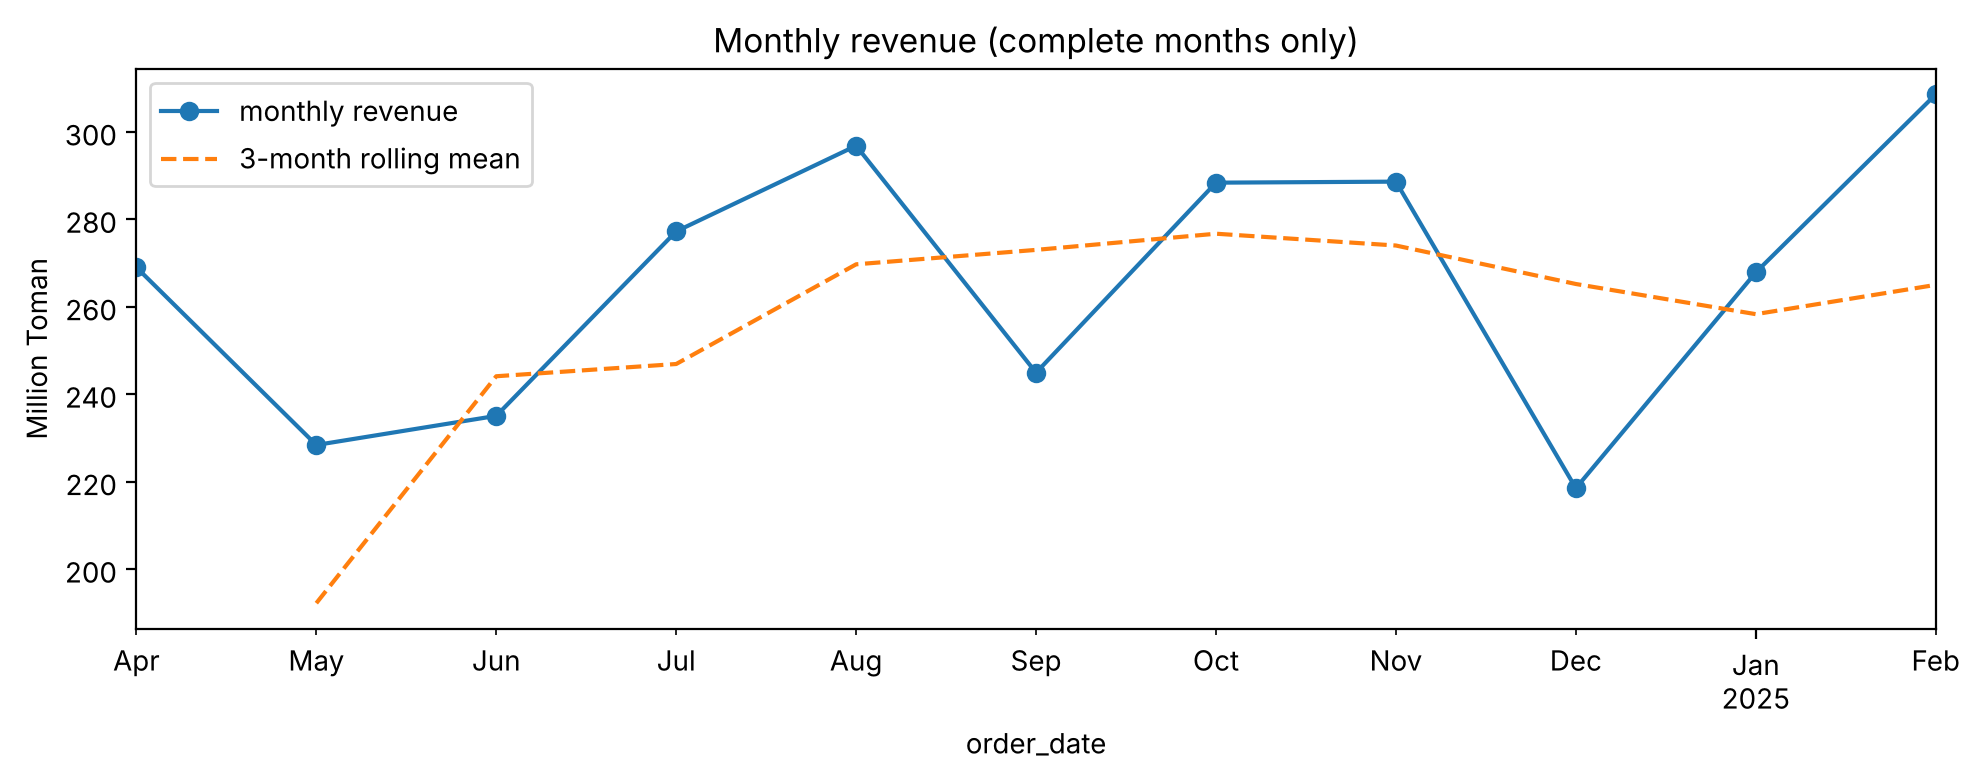

In [14]:
full_months = monthly.iloc[1:-1]          # drop the two partial months
ax = full_months["revenue_m"].plot(marker="o", figsize=(10, 4), label="monthly revenue")
full_months["rolling_3m"].plot(ax=ax, linestyle="--", label="3-month rolling mean")
ax.set_ylabel("Million Toman")
ax.set_title("Monthly revenue (complete months only)")
ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. چسباندن جدول‌ها با `concat`

وقتی داده در چند فایل با ستون‌های یکسان پخش شده است (مثلاً یک فایل برای هر فصل)، آن‌ها را با `concat` روی هم می‌چسبانیم. پارامتر `keys` منشأ هر سطر را نگه می‌دارد.

</div>

In [15]:
q1 = df[df["order_date"] < "2024-06-21"]
q2 = df[(df["order_date"] >= "2024-06-21") & (df["order_date"] < "2024-09-22")]
combined = pd.concat([q1, q2], keys=["spring", "summer"], names=["season", "row"])
combined.groupby(level="season")["total_price"].agg(["count", "sum"])

,count,sum
season,,
spring,308,757324000
summer,317,762952000


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. دادهٔ پهن و بلند: `melt` و `pivot`

یک جدول را می‌توان به دو شکل نوشت:

- **پهن (wide)**: هر متغیر یک ستون؛ برای خواندن انسان راحت است.
- **بلند (long)**: هر سطر یک مشاهده؛ برای Seaborn، گروه‌بندی و پایگاه داده مناسب است.

دادهٔ کلاسیک `flights` (تعداد مسافران ماهانهٔ خطوط هوایی ۱۹۴۹ تا ۱۹۶۰) را ببینیم:

</div>

In [16]:
flights = pd.read_csv(DATA_URL + "flights.csv")
print(flights.shape)
flights.head()

(144, 3)


,year,month,passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


In [17]:
wide = flights.pivot(index="year", columns="month", values="passengers")
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
wide = wide[month_order]
wide.head()

month,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201


In [18]:
long_again = wide.reset_index().melt(id_vars="year", var_name="month", value_name="passengers")
print(long_again.shape)
long_again.head()

(144, 3)


,year,month,passengers
0,1949,January,112
1,1950,January,115
2,1951,January,145
3,1952,January,171
4,1953,January,196


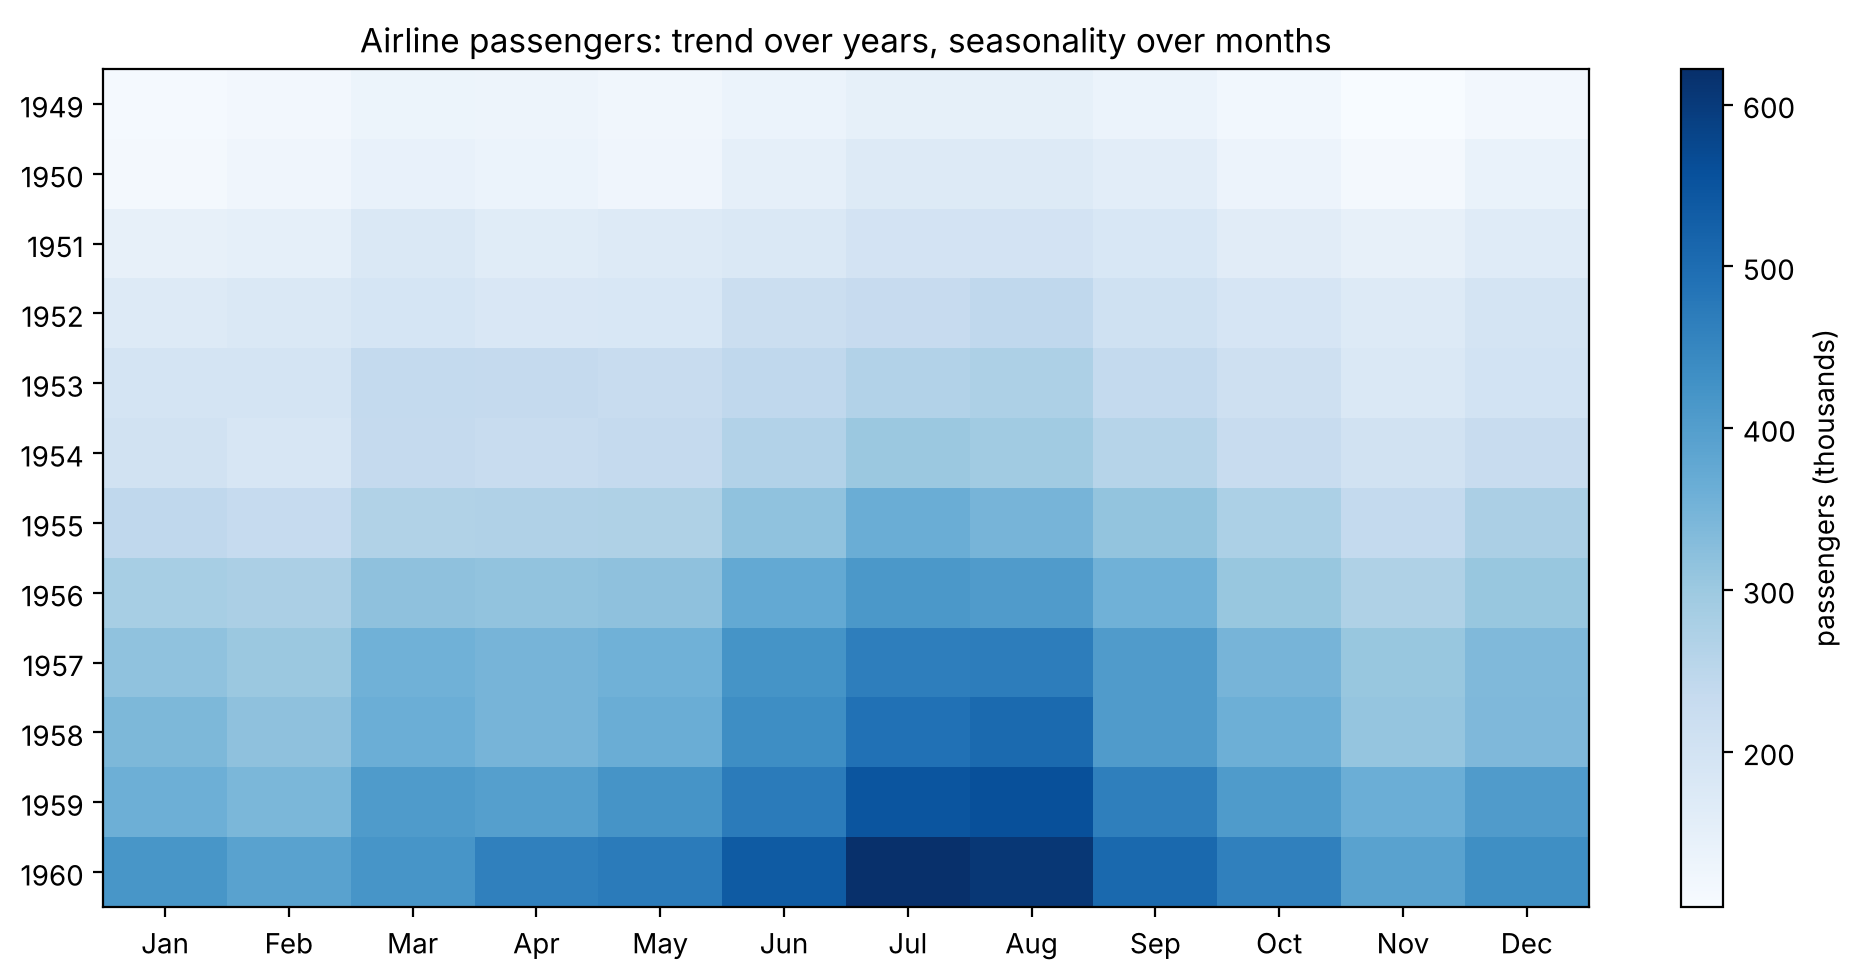

In [19]:
plt.figure(figsize=(10, 5))
plt.imshow(wide, aspect="auto", cmap="Blues")
plt.colorbar(label="passengers (thousands)")
plt.xticks(range(12), [m[:3] for m in month_order])
plt.yticks(range(len(wide)), wide.index)
plt.title("Airline passengers: trend over years, seasonality over months")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در نمودار بالا دو الگو پیداست: رنگ‌ها از بالا به پایین روشن‌تر می‌شوند (**روند** افزایشی سال‌به‌سال) و در هر سال، ماه‌های تیر و مرداد (Jul و Aug) روشن‌ترند (**فصلی بودن**).

## جمع‌بندی

- `merge` با `validate` و بررسی تعداد سطرها؛ `indicator` برای پیدا کردن بی‌جفت‌ها.
- `groupby` + `agg` برای خلاصهٔ هر گروه، `transform` برای برگرداندن نتیجه به سطرها، `filter` برای حذف گروه‌ها.
- `pivot_table` و `crosstab` برای گزارش‌های دوبعدی.
- `resample` برای خلاصهٔ زمانی، `pct_change` برای رشد و `rolling` برای میانگین متحرک.
- `melt` و `pivot` برای جابه‌جایی بین شکل پهن و بلند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. پرفروش‌ترین کالای هر دسته (بر اساس مبلغ) چیست؟ (راهنما: `groupby` دوسطحی و بعد `idxmax`)

۲. سن هر مشتری را در زمان سفارش حساب کنید و میانگین مبلغ سفارش را به تفکیک دههٔ سنی (۲۰، ۳۰، ...) گزارش کنید.

۳. برای هر مشتری، فاصلهٔ زمانی بین ثبت‌نام و **اولین** سفارش را به روز حساب کنید.

۴. جدولی بسازید که سطرهایش روزهای هفته و ستون‌هایش ساعت‌های روز باشد و تعداد سفارش‌ها را نشان دهد. پرترافیک‌ترین زمان کدام است؟

۵. در دادهٔ `flights`، رشد سالانهٔ کل مسافران را با `pct_change` حساب کنید. کدام سال بیشترین رشد را داشته است؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** پرفروش‌ترین کالای هر دسته (بر اساس مبلغ) چیست؟ (راهنما: `groupby` دوسطحی و بعد `idxmax`)

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** سن هر مشتری را در زمان سفارش حساب کنید و میانگین مبلغ سفارش را به تفکیک دههٔ سنی (۲۰، ۳۰، ...) گزارش کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** برای هر مشتری، فاصلهٔ زمانی بین ثبت‌نام و **اولین** سفارش را به روز حساب کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** جدولی بسازید که سطرهایش روزهای هفته و ستون‌هایش ساعت‌های روز باشد و تعداد سفارش‌ها را نشان دهد. پرترافیک‌ترین زمان کدام است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** در دادهٔ `flights`، رشد سالانهٔ کل مسافران را با `pct_change` حساب کنید. کدام سال بیشترین رشد را داشته است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
